<a href="https://colab.research.google.com/github/onumaechimargaret-wq/My-Project-work-gas-adsorption-modelling-python/blob/Static-Branch/project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for fpdf: filename=fpdf-1.7.2-py2.py3-none-any.whl size=40760 sha256=e823320d64afa7862778b0c2c6dc4d2499c718c235d4a96a1dd9d7dea42ab05c
  Stored in directory: /root/.cache/pip/wheels/aa/da/11/a3189f34ddc13c26a2d0f329eac46b728c7f31c39e4dc26243
Successfully built fpdf
Romulus N2 Langmuir Parameters: qm = 2.5419, b = 4.35e-06
Romulus O2 Langmuir Parameters: qm = 4.7049, b = 3.41e-07
Remus N2 Langmuir Parameters: qm = 2.8344, b = 9.80e-07
Remus O2 Langmuir Parameters: qm = 6.0977, b = 1.69e-07


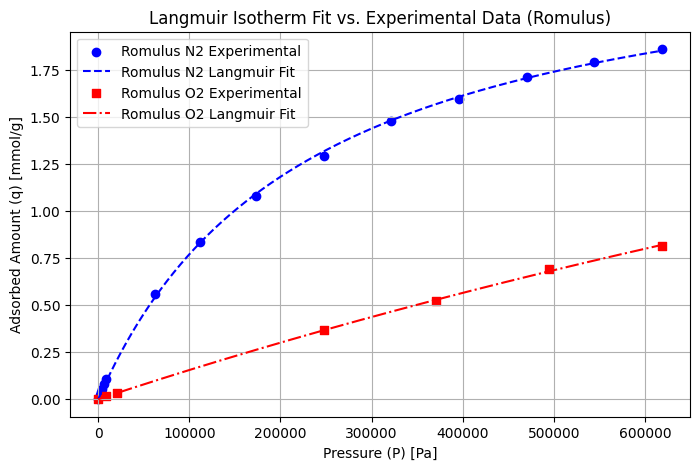

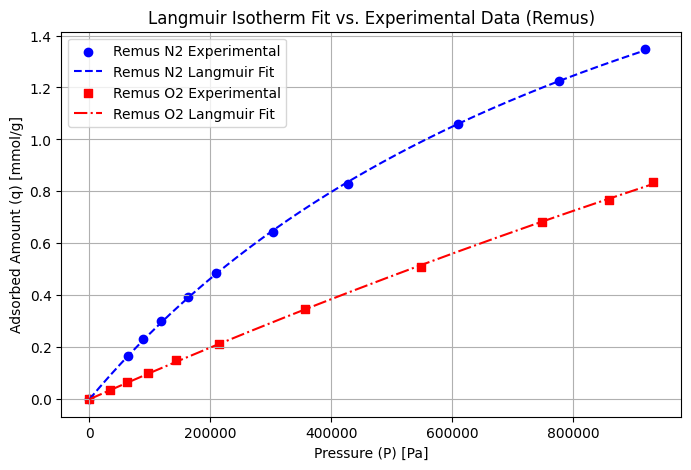

Romulus N2 Freundlich Parameters: KF = 1.7090e-03, n = 1.8910
Romulus O2 Freundlich Parameters: KF = 6.3204e-06, n = 1.1321
Remus N2 Freundlich Parameters: KF = 7.2588e-05, n = 1.3934
Remus O2 Freundlich Parameters: KF = 2.6593e-06, n = 1.0862


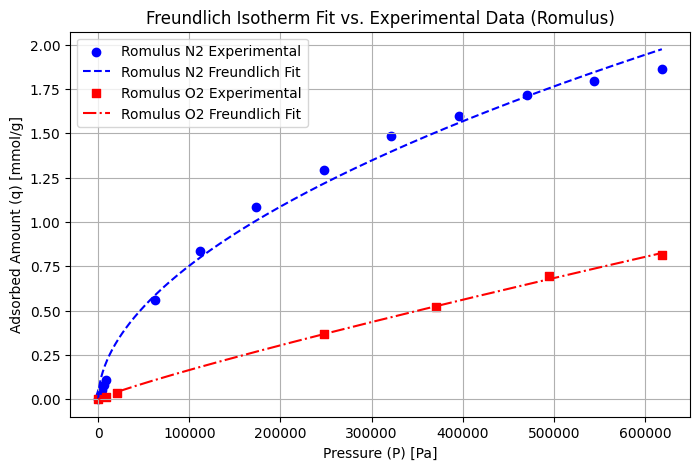

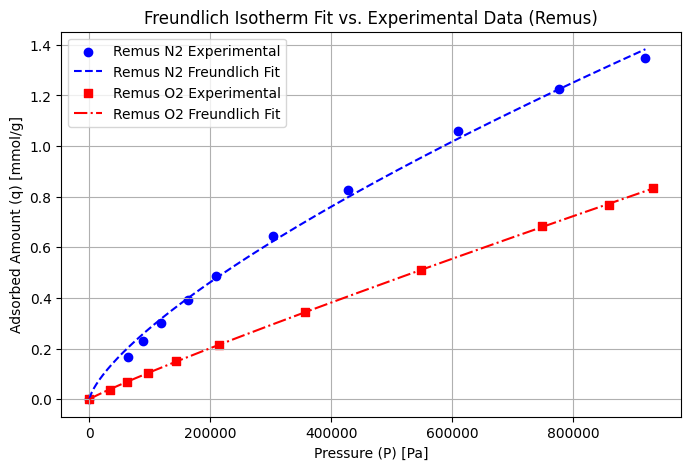

--- LANGMUIR RESULTS ---
Romulus N2: qm = 2.5419, b = 4.35e-06 | R2 = 0.9997, RMSE = 0.0122
Romulus O2: qm = 4.7049, b = 3.41e-07 | R2 = 0.9996, RMSE = 0.0063
Remus N2: qm = 2.8344, b = 9.80e-07 | R2 = 0.9999, RMSE = 0.0043
Remus O2: qm = 6.0977, b = 1.69e-07 | R2 = 0.9998, RMSE = 0.0045

--- FREUNDLICH RESULTS ---
Romulus N2: KF = 1.7090e-03, n = 1.8910 | R2 = 0.9906, RMSE = 0.0700
Romulus O2: KF = 6.3204e-06, n = 1.1321 | R2 = 0.9994, RMSE = 0.0076
Remus N2: KF = 7.2588e-05, n = 1.3934 | R2 = 0.9971, RMSE = 0.0231
Remus O2: KF = 2.6593e-06, n = 1.0862 | R2 = 0.9999, RMSE = 0.0022
Successfully saved parameters to Isotherm_Parameters_Report.pdf!


In [ ]:
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
!pip install fpdf
from fpdf import FPDF

#____________________________________
#Static adsorption data from table 1
#_____________________________________
# Romulus experimental data
P_Romulus_N2 = np.array([0, 2026.5, 3039.75, 4053, 6079.5, 8106, 61909.5, 111356.2, 173265.8, 247435.7, 321706.9, 395978.1, 470148, 544419.2, 618690.5])
q_Romulus_N2 = np.array([0, 0.025, 0.038, 0.053, 0.079, 0.108, 0.562, 0.835, 1.082, 1.295, 1.482, 1.597, 1.714, 1.795, 1.861])

P_Romulus_O2 = np.array([0, 8106, 20265, 247435.7, 371153.5, 494871.3, 618690.5])
q_Romulus_O2 = np.array([0, 0.015, 0.035, 0.366, 0.521, 0.693, 0.815])

# Remus experimental data
P_Remus_N2 = np.array([0, 63400, 88700, 117500, 162500, 208500, 303800, 427000, 609500, 776600, 919000])
q_Remus_N2 = np.array([0, 0.1674, 0.2300, 0.2994, 0.3934, 0.4848, 0.6450, 0.8280, 1.0588, 1.2249, 1.3472])

P_Remus_O2 = np.array([0, 33200, 61300, 96100, 143200, 214800, 355900, 548200, 747900, 859000, 931700])
q_Remus_O2 = np.array([0, 0.0372, 0.0679, 0.1022, 0.1504, 0.2138, 0.3455, 0.5089, 0.6830, 0.7679, 0.8348])

#We define the Langmuir isotherm function (q = qmax * b * P / (1 + b * P)) and use Python's non-linear least-squares fitting tool (curve_fit) to extract parameters qm and b for each gas and adsorbent.

def langmuir(P, qmax, b):
    q = (qmax * b * P)/(1 + b * P)
    return q

# Fit Langmuir parameters for Romulus & Remus
popt_R_N2, _ = curve_fit(langmuir, P_Romulus_N2, q_Romulus_N2, p0=[2.0, 1e-5], maxfev=10000)
popt_R_O2, _ = curve_fit(langmuir, P_Romulus_O2, q_Romulus_O2, p0=[2.0, 1e-5], maxfev=10000)
popt_Re_N2, _ = curve_fit(langmuir, P_Remus_N2, q_Remus_N2, p0=[2.0, 1e-5], maxfev=10000)
popt_Re_O2, _ = curve_fit(langmuir, P_Remus_O2, q_Remus_O2, p0=[2.0, 1e-5], maxfev=10000)

print(f"Romulus N2 Langmuir Parameters: qm = {popt_R_N2[0]:.4f}, b = {popt_R_N2[1]:.2e}")
print(f"Romulus O2 Langmuir Parameters: qm = {popt_R_O2[0]:.4f}, b = {popt_R_O2[1]:.2e}")
print(f"Remus N2 Langmuir Parameters: qm = {popt_Re_N2[0]:.4f}, b = {popt_Re_N2[1]:.2e}")
print(f"Remus O2 Langmuir Parameters: qm = {popt_Re_O2[0]:.4f}, b = {popt_Re_O2[1]:.2e}")

# Generate fitting curves data for plotting
P_fit_Romulus_N2 = np.linspace(0, np.max(P_Romulus_N2), 500)
P_fit_Romulus_O2 = np.linspace(0, np.max(P_Romulus_O2), 500)
P_fit_Remus_N2 = np.linspace(0, np.max(P_Remus_N2), 500)
P_fit_Remus_O2 = np.linspace(0, np.max(P_Remus_O2), 500)

q_fit_Romulus_N2 = langmuir(P_fit_Romulus_N2, *popt_R_N2)
q_fit_Romulus_O2 = langmuir(P_fit_Romulus_O2, *popt_R_O2)
q_fit_Remus_N2 = langmuir(P_fit_Remus_N2, *popt_Re_N2)
q_fit_Remus_O2 = langmuir(P_fit_Remus_O2, *popt_Re_O2)

# Plot 1: Romulus Curve Fit
plt.figure(figsize=(8, 5))
plt.scatter(P_Romulus_N2, q_Romulus_N2, color='blue', label='Romulus N2 Experimental', marker='o')
plt.plot(P_fit_Romulus_N2, q_fit_Romulus_N2, color='blue', linestyle='--', label='Romulus N2 Langmuir Fit')
plt.scatter(P_Romulus_O2, q_Romulus_O2, color='red', label='Romulus O2 Experimental', marker='s')
plt.plot(P_fit_Romulus_O2, q_fit_Romulus_O2, color='red', linestyle='-.', label='Romulus O2 Langmuir Fit')
plt.xlabel('Pressure (P) [Pa]')
plt.ylabel('Adsorbed Amount (q) [mmol/g]')
plt.title('Langmuir Isotherm Fit vs. Experimental Data (Romulus)')
plt.legend()
plt.grid(True)

# ---> SAVE THE PLOT HERE <---
plt.savefig('Langmuir_Romulus.png', dpi=300, bbox_inches='tight')
# You can also save as PDF for high-res reports:
# plt.savefig('Langmuir_Romulus.pdf', bbox_inches='tight')
plt.show()

# Plot 2: Remus Curve Fit
plt.figure(figsize=(8, 5))
plt.scatter(P_Remus_N2, q_Remus_N2, color='blue', label='Remus N2 Experimental', marker='o')
plt.plot(P_fit_Remus_N2, q_fit_Remus_N2, color='blue', linestyle='--', label='Remus N2 Langmuir Fit')
plt.scatter(P_Remus_O2, q_Remus_O2, color='red', label='Remus O2 Experimental', marker='s')
plt.plot(P_fit_Remus_O2, q_fit_Remus_O2, color='red', linestyle='-.', label='Remus O2 Langmuir Fit')
plt.xlabel('Pressure (P) [Pa]')
plt.ylabel('Adsorbed Amount (q) [mmol/g]')
plt.title('Langmuir Isotherm Fit vs. Experimental Data (Remus)')
plt.legend()
plt.grid(True)

# Save Remus Langmuir plot
plt.savefig('Langmuir_Remus.png', dpi=300, bbox_inches='tight')
# You can also save as PDF for high-res reports:
# plt.savefig('Langmuir_Remus.pdf', bbox_inches='tight')
plt.show()


# Define the Freundlich isotherm function (q = KF * P ** (1 / n))

# Note: We filter out P = 0 data points during fitting to avoid division by zero or 0**negative warnings.

def freundlich(P, KF, n):
    return KF * (P ** (1 / n))

# Helper function to fit while ignoring P = 0 points for numerical stability

def fit_freundlich(P, q, p0=[1.0, 2.0]):
    mask = P > 0
    popt, _ = curve_fit(freundlich, P[mask], q[mask], p0=p0, maxfev=10000)
    return popt

# Fit Freundlich parameters for Romulus & Remus
popt_R_N2 = fit_freundlich(P_Romulus_N2, q_Romulus_N2)
popt_R_O2 = fit_freundlich(P_Romulus_O2, q_Romulus_O2)
popt_Re_N2 = fit_freundlich(P_Remus_N2, q_Remus_N2)
popt_Re_O2 = fit_freundlich(P_Remus_O2, q_Remus_O2)

# Print parameters
print(f"Romulus N2 Freundlich Parameters: KF = {popt_R_N2[0]:.4e}, n = {popt_R_N2[1]:.4f}")
print(f"Romulus O2 Freundlich Parameters: KF = {popt_R_O2[0]:.4e}, n = {popt_R_O2[1]:.4f}")
print(f"Remus N2 Freundlich Parameters: KF = {popt_Re_N2[0]:.4e}, n = {popt_Re_N2[1]:.4f}")
print(f"Remus O2 Freundlich Parameters: KF = {popt_Re_O2[0]:.4e}, n = {popt_Re_O2[1]:.4f}")

# Generate fitting curves data for plotting
P_fit_Romulus_N2 = np.linspace(1, np.max(P_Romulus_N2), 500)
P_fit_Romulus_O2 = np.linspace(1, np.max(P_Romulus_O2), 500)
P_fit_Remus_N2 = np.linspace(1, np.max(P_Remus_N2), 500)
P_fit_Remus_O2 = np.linspace(1, np.max(P_Remus_O2), 500)

q_fit_Romulus_N2 = freundlich(P_fit_Romulus_N2, *popt_R_N2)
q_fit_Romulus_O2 = freundlich(P_fit_Romulus_O2, *popt_R_O2)
q_fit_Remus_N2 = freundlich(P_fit_Remus_N2, *popt_Re_N2)
q_fit_Remus_O2 = freundlich(P_fit_Remus_O2, *popt_Re_O2)

# Plot 1: Romulus Curve Fit
plt.figure(figsize=(8, 5))
plt.scatter(P_Romulus_N2, q_Romulus_N2, color='blue', label='Romulus N2 Experimental', marker='o')
plt.plot(P_fit_Romulus_N2, q_fit_Romulus_N2, color='blue', linestyle='--', label='Romulus N2 Freundlich Fit')
plt.scatter(P_Romulus_O2, q_Romulus_O2, color='red', label='Romulus O2 Experimental', marker='s')
plt.plot(P_fit_Romulus_O2, q_fit_Romulus_O2, color='red', linestyle='-.', label='Romulus O2 Freundlich Fit')
plt.xlabel('Pressure (P) [Pa]')
plt.ylabel('Adsorbed Amount (q) [mmol/g]')
plt.title('Freundlich Isotherm Fit vs. Experimental Data (Romulus)')
plt.legend()
plt.grid(True)
# Save Romulus Freundlich plot
plt.savefig('Freundlich_Romulus.png', dpi=300, bbox_inches='tight')
plt.show()

# Plot 2: Remus Curve Fit
plt.figure(figsize=(8, 5))
plt.scatter(P_Remus_N2, q_Remus_N2, color='blue', label='Remus N2 Experimental', marker='o')
plt.plot(P_fit_Remus_N2, q_fit_Remus_N2, color='blue', linestyle='--', label='Remus N2 Freundlich Fit')
plt.scatter(P_Remus_O2, q_Remus_O2, color='red', label='Remus O2 Experimental', marker='s')
plt.plot(P_fit_Remus_O2, q_fit_Remus_O2, color='red', linestyle='-.', label='Remus O2 Freundlich Fit')
plt.xlabel('Pressure (P) [Pa]')
plt.ylabel('Adsorbed Amount (q) [mmol/g]')
plt.title('Freundlich Isotherm Fit vs. Experimental Data (Remus)')
plt.legend()
plt.grid(True)
# Save Romulus Freundlich plot
plt.savefig('Freundlich_Remus.png', dpi=300, bbox_inches='tight')
plt.show()

# ____________________________________
# Helper Function for R2 and RMSE
# _____________________________________
def calculate_metrics(q_exp, q_pred):
    residuals = q_exp - q_pred
    ss_res = np.sum(residuals**2)
    ss_tot = np.sum((q_exp - np.mean(q_exp))**2)
    r2 = 1 - (ss_res / ss_tot)
    rmse = np.sqrt(np.mean(residuals**2))
    return r2, rmse

# ____________________________________
# Langmuir Isotherm Fit & Metrics
# _____________________________________
def langmuir(P, qmax, b):
    return (qmax * b * P) / (1 + b * P)

datasets = [
    ("Romulus N2", P_Romulus_N2, q_Romulus_N2),
    ("Romulus O2", P_Romulus_O2, q_Romulus_O2),
    ("Remus N2", P_Remus_N2, q_Remus_N2),
    ("Remus O2", P_Remus_O2, q_Remus_O2)
]

print("--- LANGMUIR RESULTS ---")
langmuir_results = {}
for name, P, q in datasets:
    popt, _ = curve_fit(langmuir, P, q, p0=[2.0, 1e-5], maxfev=10000)
    q_pred = langmuir(P, *popt)
    r2, rmse = calculate_metrics(q, q_pred)
    langmuir_results[name] = {"popt": popt, "R2": r2, "RMSE": rmse}
    print(f"{name}: qm = {popt[0]:.4f}, b = {popt[1]:.2e} | R2 = {r2:.4f}, RMSE = {rmse:.4f}")

# ____________________________________
# Freundlich Isotherm Fit & Metrics
# _____________________________________
def freundlich(P, KF, n):
    return KF * (P ** (1 / n))

print("\n--- FREUNDLICH RESULTS ---")
freundlich_results = {}
for name, P, q in datasets:
    # Filter out P = 0 for fitting stability
    mask = P > 0
    popt, _ = curve_fit(freundlich, P[mask], q[mask], p0=[1.0, 2.0], maxfev=10000)

    # Calculate predictions on the full dataset (including P=0 where q=0)
    q_pred = freundlich(P, *popt)
    r2, rmse = calculate_metrics(q, q_pred)
    freundlich_results[name] = {"popt": popt, "R2": r2, "RMSE": rmse}
    print(f"{name}: KF = {popt[0]:.4e}, n = {popt[1]:.4f} | R2 = {r2:.4f}, RMSE = {rmse:.4f}")


# Create a PDF class for layout styling
class IsothermPDF(FPDF):
    def header(self):
        # Title
        self.set_font('Arial', 'B', 14)
        self.cell(0, 10, 'Adsorption Isotherm Fitting Report', 0, 1, 'C')
        self.ln(5)

    def footer(self):
        # Page number
        self.set_y(-15)
        self.set_font('Arial', 'I', 8)
        self.cell(0, 10, f'Page {self.page_no()}', 0, 0, 'C')

# Initialize PDF
pdf = IsothermPDF()
pdf.add_page()
pdf.set_font('Arial', size=11)

# Add introduction text
pdf.cell(0, 10, 'Summary of Langmuir and Freundlich Isotherm Model Parameters:', 0, 1)
pdf.ln(3)

# Function to add results to the PDF table/text
def write_results_to_pdf(title, results_dict, model_type):
    pdf.set_font('Arial', 'B', 12)
    pdf.cell(0, 8, title, 0, 1)
    pdf.set_font('Arial', size=10)

    for name, res in results_dict.items():
        if model_type == 'Langmuir':
            text = f"  - {name}: qm = {res['popt'][0]:.4f}, b = {res['popt'][1]:.2e} | R2 = {res['R2']:.4f}, RMSE = {res['RMSE']:.4f}"
        else: # Freundlich
            text = f"  - {name}: KF = {res['popt'][0]:.4e}, n = {res['popt'][1]:.4f} | R2 = {res['R2']:.4f}, RMSE = {res['RMSE']:.4f}"
        pdf.cell(0, 6, text, 0, 1)
    pdf.ln(5)

# Write Langmuir and Freundlich results to the PDF
write_results_to_pdf("Langmuir Isotherm Results", langmuir_results, 'Langmuir')
write_results_to_pdf("Freundlich Isotherm Results", freundlich_results, 'Freundlich')

# Save the PDF file
pdf_filename = "Isotherm_Parameters_Report.pdf"
pdf.output(pdf_filename)
print(f"Successfully saved parameters to {pdf_filename}!")


LOW-PRESSURE (HENRY) SELECTIVITY  qmax*b(N2) / qmax*b(O2)
  Romulus : 6.88
  Remus   : 2.70
Successfully saved parameters to Selectivity_Report.pdf!

SELECTIVITY q_N2/q_O2 AT THE SAME PRESSURE
  P [kPa]      Romulus     Remus   Romulus/Remus
       10         6.62      2.68         2.47
       50         5.75      2.60         2.22
      100         4.96      2.50         1.98
      250         3.58      2.26         1.58
      500         2.54      1.96         1.29
      900         1.83      1.65         1.11

CHECK: Romulus selectivity from raw data vs fitted model
  P =  247.4 kPa: data = 3.54, model = 3.60
  P =  618.7 kPa: data = 2.28, model = 2.26
Successfully saved parameters to Selectivity_Report.pdf!

Figure saved as selectivity_comparison.png
Successfully saved parameters to Selectivity_Report.pdf!


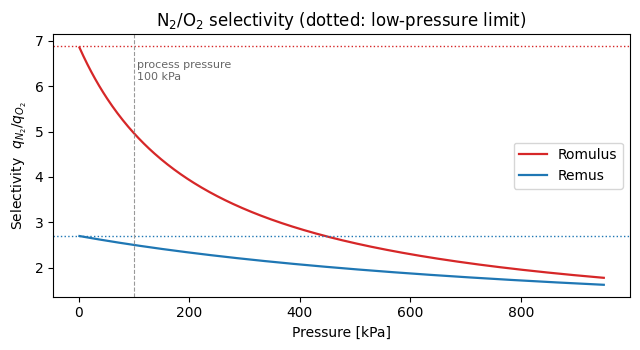

In [3]:
"""
Compare the N2/O2 selectivity of Romulus and Remus using the fitted Langmuir isotherms.

Selectivity here = (amount of N2 adsorbed) / (amount of O2 adsorbed).
A higher value means the adsorbent removes N2 more strongly than it holds O2,
which is what an oxygen concentrator needs.

We compute it in two ways:
  1. Low-pressure (Henry) selectivity: the ratio of the initial isotherm slopes, qmax*b(N2) / qmax*b(O2).
     This is the limit as pressure -> 0.
  2. Pressure-dependent selectivity: q_N2(P) / q_O2(P) at the SAME pressure P for both gases.
"""

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt

# Selectivity

# Fitted Langmuir parameters from step 1 (isotherm_fit_simple.py): qmax [mol/kg], b [1/Pa]
iso = {
    "Romulus": {"N2": (2.5419147866720593, 4.349855816324839e-06),
                "O2": (4.704886024767367,  3.413976359526567e-07)},
    "Remus":   {"N2": (2.8343537846190325, 9.801468351520296e-07),
                "O2": (6.097655270245227,  1.6875286962753394e-07)},
}

def langmuir(P, qmax, b):
    q = qmax * b * P / (1.0 + b * P)
    return q

adsorbents = ["Romulus", "Remus"]

# ---------------------------------------------------------------
# 1. LOW-PRESSURE (HENRY) SELECTIVITY
# ---------------------------------------------------------------
def henry_selectivity(name):
    qmax_N2, b_N2 = iso[name]["N2"]
    qmax_O2, b_O2 = iso[name]["O2"]
    return (qmax_N2 * b_N2) / (qmax_O2 * b_O2)

print("LOW-PRESSURE (HENRY) SELECTIVITY  qmax*b(N2) / qmax*b(O2)")
for name in adsorbents:
    print(f"  {name:8s}: {henry_selectivity(name):.2f}")
    # Save the PDF file
pdf_filename = "Selectivity_Report.pdf"
print(f"Successfully saved parameters to {pdf_filename}!")


# ---------------------------------------------------------------
# 2. SELECTIVITY AT THE SAME PRESSURE
# ---------------------------------------------------------------
def selectivity_at(name, P):
    """q_N2(P) / q_O2(P), with P in Pa."""
    return langmuir(P, *iso[name]["N2"]) / langmuir(P, *iso[name]["O2"])

print("\nSELECTIVITY q_N2/q_O2 AT THE SAME PRESSURE")
print("  P [kPa]   " + "".join(f"{n:>10s}" for n in adsorbents) + "   Romulus/Remus")
for P_kPa in (10, 50, 100, 250, 500, 900):
    s = [selectivity_at(n, P_kPa * 1e3) for n in adsorbents]
    print(f"  {P_kPa:7d}   " + "".join(f"{x:10.2f}" for x in s) + f"   {s[0] / s[1]:10.2f}")

# ---------------------------------------------------------------
# 3. CHECK AGAINST RAW DATA (Romulus has N2 and O2 measured at the same two pressures)
# ---------------------------------------------------------------
raw = {247435.65: (1.295, 0.366),     # P [Pa]: (q_N2, q_O2) from Table 1
       618690.45: (1.861, 0.815)}
print("\nCHECK: Romulus selectivity from raw data vs fitted model")
for P, (qN, qO) in raw.items():
    print(f"  P = {P/1e3:6.1f} kPa: data = {qN / qO:.2f}, model = {selectivity_at('Romulus', P):.2f}")
    # Save the PDF file
pdf_filename = "Selectivity_Report.pdf"
print(f"Successfully saved parameters to {pdf_filename}!")


# ---------------------------------------------------------------
# 4. FIGURE
# ---------------------------------------------------------------
P = np.linspace(1e3, 950e3, 400)
colours = {"Romulus": "tab:red", "Remus": "tab:blue"}

fig, ax = plt.subplots(figsize=(6.5, 3.6))
for name in adsorbents:
    ax.plot(P / 1e3, selectivity_at(name, P), color=colours[name], lw=1.6, label=name)
    ax.axhline(henry_selectivity(name), color=colours[name], ls=":", lw=1)   # low-pressure limit
ax.axvline(100, color="0.6", ls="--", lw=0.8)
ax.text(105, ax.get_ylim()[1] * 0.92, "process pressure\n100 kPa", fontsize=8, color="0.4", va="top")
ax.set_xlabel("Pressure [kPa]")
ax.set_ylabel("Selectivity  $q_{N_2}/q_{O_2}$")
ax.set_title("N$_2$/O$_2$ selectivity (dotted: low-pressure limit)")
ax.legend()
plt.tight_layout()
plt.savefig("selectivity_comparison.png", dpi=200)
print("\nFigure saved as selectivity_comparison.png")

# Save the PDF file
pdf_filename = "Selectivity_Report.pdf"
print(f"Successfully saved parameters to {pdf_filename}!")


In [ ]:
# Equilibrium Theory

